# Question 3(c): Sufficient sample size

From part (b), with probability at least $1-\delta$,

$$
R(\widehat f)-R(f^*_{\mathcal F})
\le 2\sqrt{\frac{\log(2K/\delta)}{2n}}.
$$

We want this upper bound to be at most $\epsilon=0.1$, with $K=100$ and $\delta=0.05$. Squaring both sides and rearranging gives

$$
2\sqrt{\frac{\log(2K/\delta)}{2n}}\le\epsilon
\quad\Longleftrightarrow\quad
n\ge\frac{2\log(2K/\delta)}{\epsilon^2}.
$$

Since the sample size is an integer, we take the ceiling of the right-hand side.

In [3]:
import math
import numpy as np
import matplotlib.pyplot as plt

K = 100
delta = 0.05
target = 0.1

required_real = 2 * math.log(2 * K / delta) / target**2
n_min = math.ceil(required_real)

def excess_risk_bound(n):
    return 2 * np.sqrt(np.log(2 * K / delta) / (2 * np.asarray(n)))

print(f"Required real-valued threshold: {required_real:.6f}")
print(f"Smallest sufficient integer n: {n_min}")
print(f"Bound at n = {n_min - 1}: {excess_risk_bound(n_min-1):.8f}")
print(f"Bound at n = {n_min}: {excess_risk_bound(n_min):.8f}")
assert excess_risk_bound(n_min) <= target
assert excess_risk_bound(n_min-1) > target

Required real-valued threshold: 1658.809928
Smallest sufficient integer n: 1659
Bound at n = 1658: 0.10002442
Bound at n = 1659: 0.09999427


Thus **$n=1659$ samples are sufficient** to guarantee

$$
R(\widehat f)-R(f^*_{\mathcal F})\le 0.1
\quad\text{with probability at least }0.95.
$$

The following plot shows the bound as a function of sample size and the target value. This is an illustration of the analytical guarantee, not an empirical simulation.

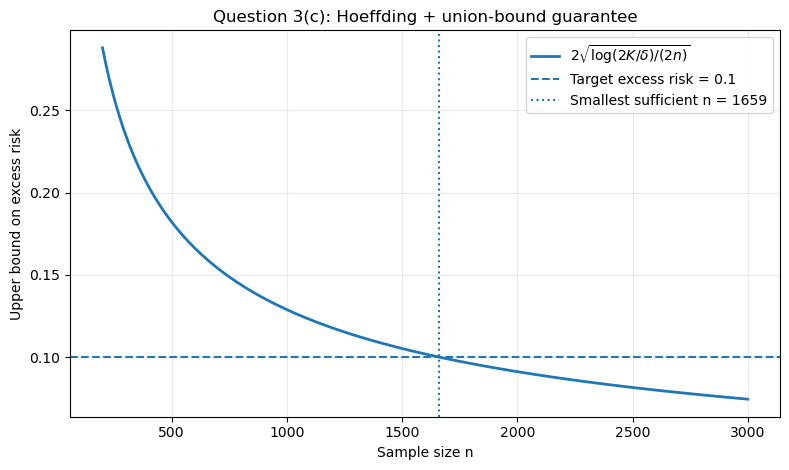

In [4]:
n_grid = np.arange(200, 3001)
bound_grid = excess_risk_bound(n_grid)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(n_grid, bound_grid, linewidth=2, label=r"$2\sqrt{\log(2K/\delta)/(2n)}$")
ax.axhline(target, linestyle="--", label="Target excess risk = 0.1")
ax.axvline(n_min, linestyle=":", label=f"Smallest sufficient n = {n_min}")
ax.set(xlabel="Sample size n", ylabel="Upper bound on excess risk",
       title="Question 3(c): Hoeffding + union-bound guarantee")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig("figures/question 3/3c_sample_size.png", dpi=200, bbox_inches="tight")
plt.show()